In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving pollution_data.csv.csv to pollution_data.csv.csv


In [2]:
df = pd.read_csv("pollution_data.csv.csv")

df.head()

,Station ID,State,City,Station Name,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),...,MP-Xylene (µg/m³),AT (°C),RH (%),WS (m/s),WD (deg),RF (mm),TOT-RF (mm),SR (W/mt2),BP (mmHg),VWS (m/s)
0,site_1563,Delhi,Delhi,"Pusa, Delhi - DPCC",2024-01-01T00:00:00.000000+0000,205.0,337.0,17.7,42.5,60.3,...,NaN,15.2,2.8,0.3,337.3,0.0,0.0,5.0,981.9,NaN
1,site_1563,Delhi,Delhi,"Pusa, Delhi - DPCC",2024-01-01T00:15:00.000000+0000,205.0,337.0,16.7,41.9,58.6,...,NaN,15.1,2.8,0.3,336.5,0.0,0.0,5.1,981.7,NaN
2,site_1563,Delhi,Delhi,"Pusa, Delhi - DPCC",2024-01-01T00:30:00.000000+0000,205.0,337.0,16.4,43.4,59.8,...,NaN,15.2,2.8,0.3,335.5,0.0,0.0,5.0,981.8,NaN
3,site_1563,Delhi,Delhi,"Pusa, Delhi - DPCC",2024-01-01T00:45:00.000000+0000,196.0,313.0,16.3,43.2,59.5,...,NaN,15.2,2.8,0.3,341.3,0.0,0.0,5.0,981.8,NaN
4,site_1563,Delhi,Delhi,"Pusa, Delhi - DPCC",2024-01-01T01:00:00.000000+0000,196.0,313.0,16.9,43.0,59.8,...,NaN,15.2,2.8,0.3,26.8,0.0,0.0,5.1,981.8,NaN


In [3]:
df.shape

(70177, 29)

In [4]:
df.columns

Index(['Station ID', 'State', 'City', 'Station Name', 'Timestamp',
       'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)', 'NO2 (µg/m³)',
       'NOx (ppb)', 'NH3 (µg/m³)', 'SO2 (µg/m³)', 'CO (mg/m³)',
       'Ozone (µg/m³)', 'Benzene (µg/m³)', 'Toluene (µg/m³)', 'Xylene (µg/m³)',
       'O Xylene (µg/m³)', 'Eth-Benzene (µg/m³)', 'MP-Xylene (µg/m³)',
       'AT (°C)', 'RH (%)', 'WS (m/s)', 'WD (deg)', 'RF (mm)', 'TOT-RF (mm)',
       'SR (W/mt2)', 'BP (mmHg)', 'VWS (m/s)'],
      dtype='object')

In [5]:
df.dtypes

,0
Station ID,object
State,object
City,object
Station Name,object
Timestamp,object
PM2.5 (µg/m³),float64
PM10 (µg/m³),float64
NO (µg/m³),float64
NO2 (µg/m³),float64
NOx (ppb),float64


In [6]:
df.isnull().sum()

,0
Station ID,0
State,1
City,1
Station Name,1
Timestamp,1
PM2.5 (µg/m³),2538
PM10 (µg/m³),2584
NO (µg/m³),5004
NO2 (µg/m³),4005
NOx (ppb),4197


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Timestamp"].head()

,Timestamp
0,2024-01-01T00:00:00.000000+0000
1,2024-01-01T00:15:00.000000+0000
2,2024-01-01T00:30:00.000000+0000
3,2024-01-01T00:45:00.000000+0000
4,2024-01-01T01:00:00.000000+0000


In [9]:
df["Timestamp"].dtype

dtype('O')

In [11]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

In [12]:
df["Timestamp"].dtype

datetime64[ns, UTC]

In [13]:
df["Timestamp"].min(), df["Timestamp"].max()

(Timestamp('2024-01-01 00:00:00+0000', tz='UTC'),
 Timestamp('2025-12-31 23:45:00+0000', tz='UTC'))

In [14]:
df["Station ID"].nunique()

2

In [15]:
df["Station ID"].unique()

array(['site_1563', '2025'], dtype=object)

In [16]:
pollutants = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "WS (m/s)",
    "RF (mm)"
]

for col in pollutants:
    print(col, ":", (df[col] < 0).sum())

PM2.5 (µg/m³) : 0
PM10 (µg/m³) : 0
NO2 (µg/m³) : 0
CO (mg/m³) : 0
WS (m/s) : 0
RF (mm) : 0


In [17]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (70177, 29)


In [18]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)

In [19]:
df = df.dropna(subset=["Timestamp"])

print("Rows after timestamp cleaning:", len(df))

Rows after timestamp cleaning: 70176


In [20]:
numeric_columns = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "AT (°C)",
    "RH (%)",
    "WS (m/s)",
    "RF (mm)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [21]:
non_negative_columns = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "WS (m/s)",
    "RF (mm)"
]

for col in non_negative_columns:
    df.loc[df[col] < 0, col] = pd.NA

In [22]:
print("Humidity below 0:", (df["RH (%)"] < 0).sum())
print("Humidity above 100:", (df["RH (%)"] > 100).sum())

Humidity below 0: 0
Humidity above 100: 0


In [23]:
df.loc[
    (df["RH (%)"] < 0) | (df["RH (%)"] > 100),
    "RH (%)"
] = pd.NA

In [24]:
df = df.sort_values("Timestamp").reset_index(drop=True)

In [25]:
df.isnull().sum()

,0
Station ID,0
State,0
City,0
Station Name,0
Timestamp,0
PM2.5 (µg/m³),2537
PM10 (µg/m³),2583
NO (µg/m³),5003
NO2 (µg/m³),4004
NOx (ppb),4196


In [26]:
df[numeric_columns] = df[numeric_columns].interpolate(
    method="linear"
)

In [27]:
df[numeric_columns] = df[numeric_columns].ffill()
df[numeric_columns] = df[numeric_columns].bfill()

In [28]:
df.isnull().sum()

,0
Station ID,0
State,0
City,0
Station Name,0
Timestamp,0
PM2.5 (µg/m³),0
PM10 (µg/m³),0
NO (µg/m³),5003
NO2 (µg/m³),0
NOx (ppb),4196


In [29]:
print("Final rows:", df.shape[0])
print("Final columns:", df.shape[1])
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Final rows: 70176
Final columns: 29
Duplicates: 0
Missing values: 388772


In [30]:
df.to_csv(
    "cleaned_pollution_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [31]:
from google.colab import files

files.download("cleaned_pollution_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
df["Date"] = df["Timestamp"].dt.date

df[["Timestamp", "Date"]].head()

,Timestamp,Date
0,2024-01-01 00:00:00+00:00,2024-01-01
1,2024-01-01 00:15:00+00:00,2024-01-01
2,2024-01-01 00:30:00+00:00,2024-01-01
3,2024-01-01 00:45:00+00:00,2024-01-01
4,2024-01-01 01:00:00+00:00,2024-01-01


In [33]:
df["Hour"] = df["Timestamp"].dt.hour

df[["Timestamp", "Hour"]].head()

,Timestamp,Hour
0,2024-01-01 00:00:00+00:00,0
1,2024-01-01 00:15:00+00:00,0
2,2024-01-01 00:30:00+00:00,0
3,2024-01-01 00:45:00+00:00,0
4,2024-01-01 01:00:00+00:00,1


In [34]:
df["Day"] = df["Timestamp"].dt.day

df[["Timestamp", "Day"]].head()

,Timestamp,Day
0,2024-01-01 00:00:00+00:00,1
1,2024-01-01 00:15:00+00:00,1
2,2024-01-01 00:30:00+00:00,1
3,2024-01-01 00:45:00+00:00,1
4,2024-01-01 01:00:00+00:00,1


In [35]:
df["Month"] = df["Timestamp"].dt.month

df[["Timestamp", "Month"]].head()

,Timestamp,Month
0,2024-01-01 00:00:00+00:00,1
1,2024-01-01 00:15:00+00:00,1
2,2024-01-01 00:30:00+00:00,1
3,2024-01-01 00:45:00+00:00,1
4,2024-01-01 01:00:00+00:00,1


In [36]:
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

df[["Timestamp", "DayOfWeek"]].head()

,Timestamp,DayOfWeek
0,2024-01-01 00:00:00+00:00,0
1,2024-01-01 00:15:00+00:00,0
2,2024-01-01 00:30:00+00:00,0
3,2024-01-01 00:45:00+00:00,0
4,2024-01-01 01:00:00+00:00,0


In [37]:
df["Is_Weekend"] = df["DayOfWeek"] >= 5

df[["Timestamp", "DayOfWeek", "Is_Weekend"]].head()

,Timestamp,DayOfWeek,Is_Weekend
0,2024-01-01 00:00:00+00:00,0,False
1,2024-01-01 00:15:00+00:00,0,False
2,2024-01-01 00:30:00+00:00,0,False
3,2024-01-01 00:45:00+00:00,0,False
4,2024-01-01 01:00:00+00:00,0,False


In [38]:
df["Day_Name"] = df["Timestamp"].dt.day_name()

df[["Timestamp", "Day_Name"]].head()

,Timestamp,Day_Name
0,2024-01-01 00:00:00+00:00,Monday
1,2024-01-01 00:15:00+00:00,Monday
2,2024-01-01 00:30:00+00:00,Monday
3,2024-01-01 00:45:00+00:00,Monday
4,2024-01-01 01:00:00+00:00,Monday


In [39]:
print(df[
    [
        "Timestamp",
        "Date",
        "Hour",
        "Day",
        "Month",
        "DayOfWeek",
        "Is_Weekend",
        "Day_Name"
    ]
].head(10))

                  Timestamp        Date  Hour  Day  Month  DayOfWeek  \
0 2024-01-01 00:00:00+00:00  2024-01-01     0    1      1          0   
1 2024-01-01 00:15:00+00:00  2024-01-01     0    1      1          0   
2 2024-01-01 00:30:00+00:00  2024-01-01     0    1      1          0   
3 2024-01-01 00:45:00+00:00  2024-01-01     0    1      1          0   
4 2024-01-01 01:00:00+00:00  2024-01-01     1    1      1          0   
5 2024-01-01 01:15:00+00:00  2024-01-01     1    1      1          0   
6 2024-01-01 01:30:00+00:00  2024-01-01     1    1      1          0   
7 2024-01-01 01:45:00+00:00  2024-01-01     1    1      1          0   
8 2024-01-01 02:00:00+00:00  2024-01-01     2    1      1          0   
9 2024-01-01 02:15:00+00:00  2024-01-01     2    1      1          0   

   Is_Weekend Day_Name  
0       False   Monday  
1       False   Monday  
2       False   Monday  
3       False   Monday  
4       False   Monday  
5       False   Monday  
6       False   Monday  
7      

In [40]:
from sklearn.preprocessing import MinMaxScaler

pollutants = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)"
]

scaler = MinMaxScaler()

df[[
    "PM25_norm",
    "PM10_norm",
    "NO2_norm",
    "CO_norm"
]] = scaler.fit_transform(df[pollutants])

In [41]:
df["Pollution_Score"] = (
    0.40 * df["PM25_norm"] +
    0.25 * df["PM10_norm"] +
    0.20 * df["NO2_norm"] +
    0.15 * df["CO_norm"]
)

In [42]:
df[
    [
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "CO (mg/m³)",
        "Pollution_Score"
    ]
].head()

,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score
0,205.0,337.0,42.5,1.3,0.203308
1,205.0,337.0,41.9,1.3,0.203064
2,205.0,337.0,43.4,1.4,0.205197
3,196.0,313.0,43.2,1.4,0.195477
4,196.0,313.0,43.0,1.3,0.193873


In [43]:
print("Minimum:", df["Pollution_Score"].min())
print("Maximum:", df["Pollution_Score"].max())
print("Average :", df["Pollution_Score"].mean())

Minimum: 0.012555851264064008
Maximum: 0.6769182249055604
Average : 0.13026914079503973


In [44]:
def classify_risk(score):
    if score >= 0.75:
        return "Critical"
    elif score >= 0.50:
        return "High"
    elif score >= 0.25:
        return "Moderate"
    else:
        return "Low"


df["Risk_Level"] = df["Pollution_Score"].apply(classify_risk)

In [45]:
df[
    ["Pollution_Score", "Risk_Level"]
].head(10)

,Pollution_Score,Risk_Level
0,0.203308,Low
1,0.203064,Low
2,0.205197,Low
3,0.195477,Low
4,0.193873,Low
5,0.194379,Low
6,0.194460,Low
7,0.196906,Low
8,0.196815,Low
9,0.196723,Low


In [46]:
df["Risk_Level"].value_counts()

,count
Risk_Level,
Low,64262
Moderate,5716
High,198


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

In [48]:
print("===== STATISTICAL SUMMARY =====")

print(df[
    [
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "CO (mg/m³)",
        "AT (°C)",
        "RH (%)",
        "WS (m/s)",
        "RF (mm)"
    ]
].describe())

===== STATISTICAL SUMMARY =====
       PM2.5 (µg/m³)  PM10 (µg/m³)   NO2 (µg/m³)    CO (mg/m³)       AT (°C)  \
count   70176.000000  70176.000000  70176.000000  70176.000000  70176.000000   
mean       91.199548    208.025051     62.581084      1.094400     26.365475   
std        87.364367    131.137597     47.057009      0.778762      7.793242   
min         1.000000      1.000000      0.100000      0.000000      3.200000   
25%        31.000000    113.000000     32.400000      0.560000     19.800000   
50%        58.000000    188.000000     52.200000      0.920000     28.500000   
75%       127.000000    277.000000     79.400000      1.480000     32.500000   
max       997.000000    997.000000    491.800000      9.850000     47.400000   

             RH (%)      WS (m/s)       RF (mm)  
count  70176.000000  70176.000000  70176.000000  
mean      60.484154      1.513849      0.064219  
std       21.197045      1.866747      0.970263  
min        2.000000      0.100000      0.000000

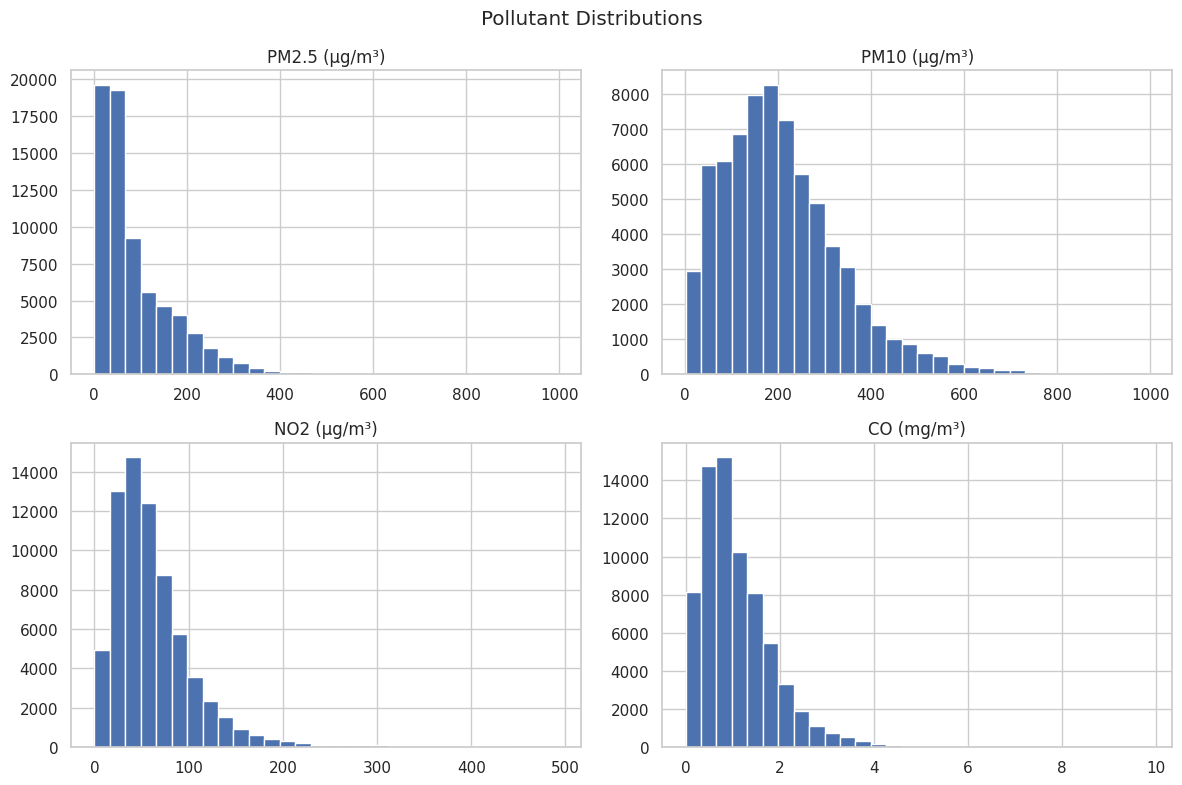

In [49]:
pollutants = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)"
]

df[pollutants].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Pollutant Distributions")
plt.tight_layout()
plt.show()

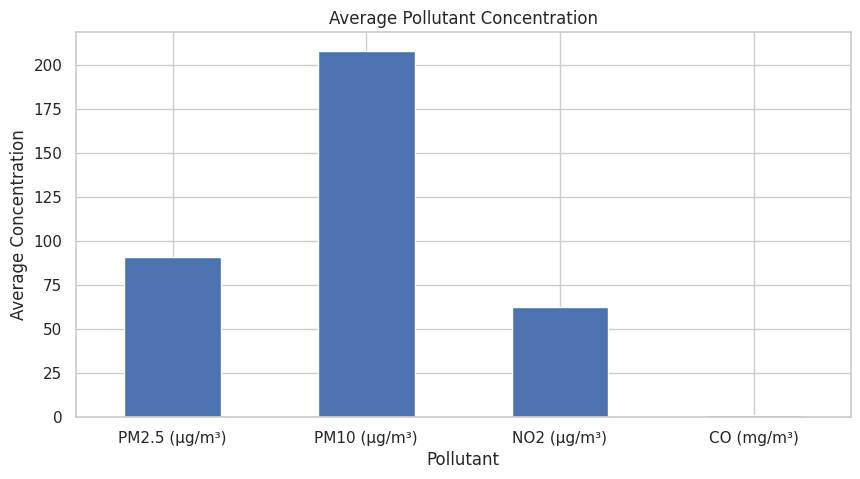

In [50]:
mean_pollution = df[pollutants].mean()

plt.figure(figsize=(10, 5))

mean_pollution.plot(kind="bar")

plt.title("Average Pollutant Concentration")
plt.xlabel("Pollutant")
plt.ylabel("Average Concentration")
plt.xticks(rotation=0)

plt.show()

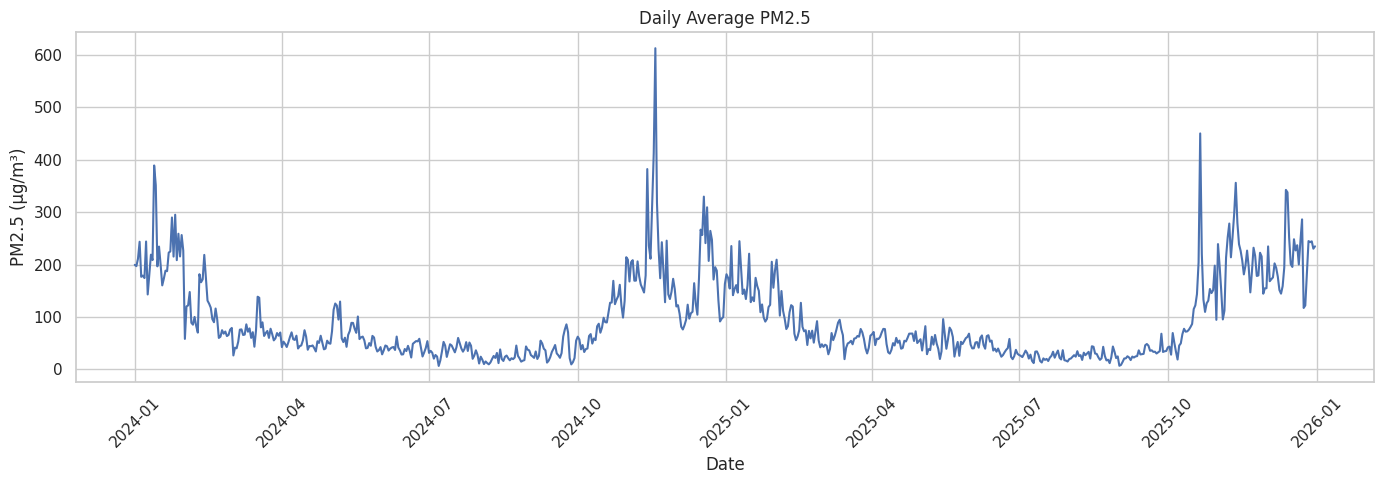

In [51]:
daily_pm25 = df.groupby("Date")["PM2.5 (µg/m³)"].mean()

plt.figure(figsize=(14, 5))

plt.plot(
    daily_pm25.index,
    daily_pm25.values
)

plt.title("Daily Average PM2.5")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

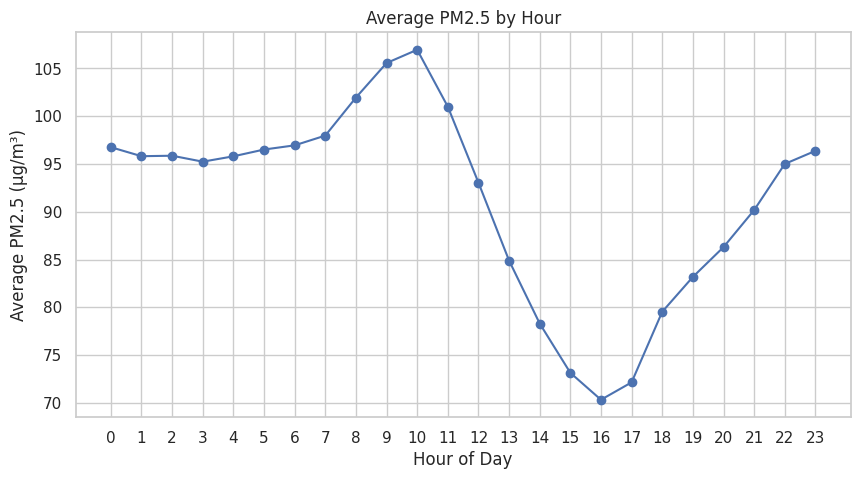

In [52]:
hourly_pm25 = df.groupby("Hour")["PM2.5 (µg/m³)"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pm25.index,
    hourly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average PM2.5 (µg/m³)")

plt.xticks(range(0, 24))

plt.grid(True)

plt.show()

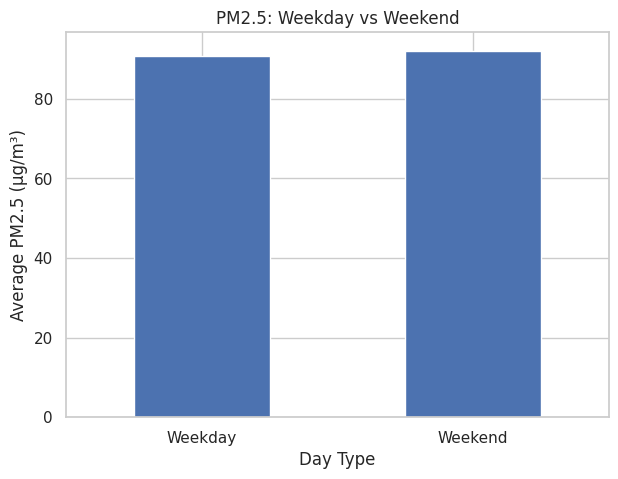

In [53]:
weekend_analysis = df.groupby(
    "Is_Weekend"
)["PM2.5 (µg/m³)"].mean()

weekend_analysis.index = [
    "Weekday" if x == False else "Weekend"
    for x in weekend_analysis.index
]

plt.figure(figsize=(7, 5))

weekend_analysis.plot(kind="bar")

plt.title("PM2.5: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=0)

plt.show()

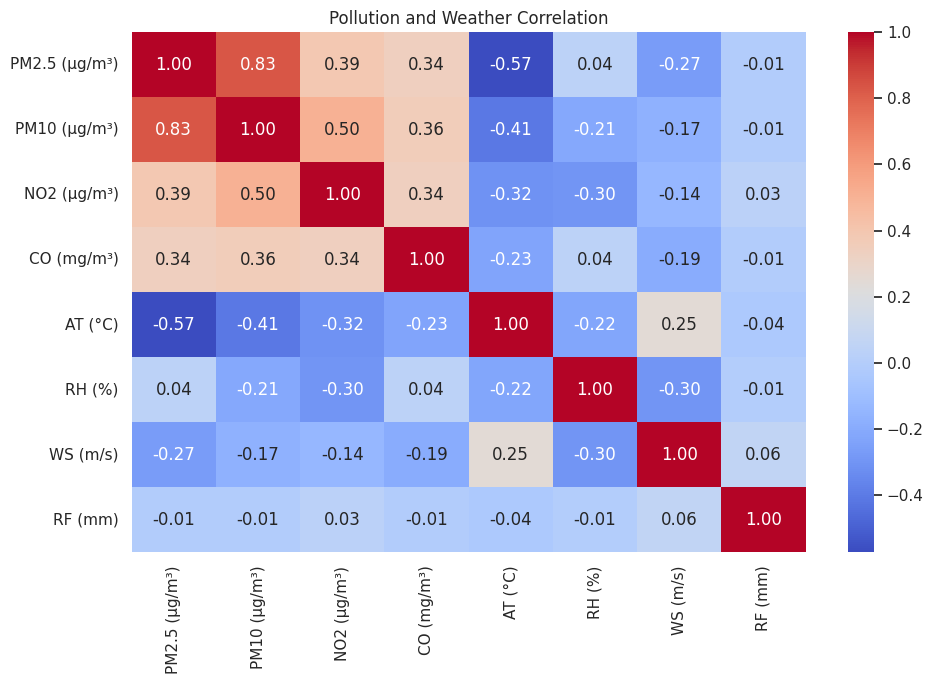

In [54]:
correlation_columns = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "AT (°C)",
    "RH (%)",
    "WS (m/s)",
    "RF (mm)"
]

correlation = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Pollution and Weather Correlation")

plt.tight_layout()
plt.show()

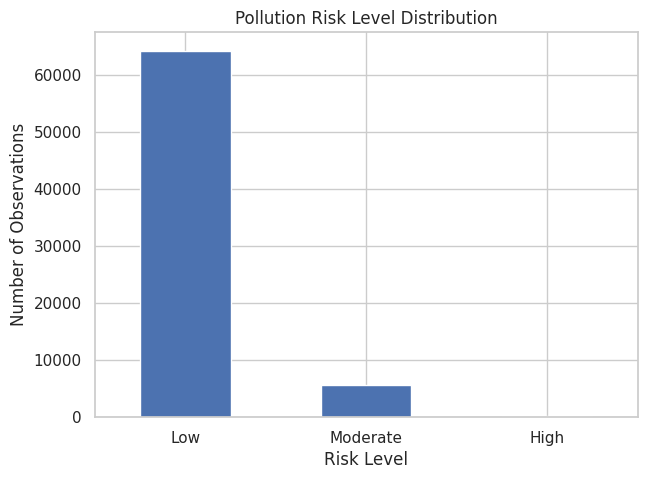

In [55]:
risk_counts = df["Risk_Level"].value_counts()

plt.figure(figsize=(7, 5))

risk_counts.plot(
    kind="bar"
)

plt.title("Pollution Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Observations")

plt.xticks(rotation=0)

plt.show()

In [56]:
print("===== IMPORTANT EDA RESULTS =====")

print("\nAverage Pollution:")
print(df[pollutants].mean())

print("\nHighest Average PM2.5 Hour:")
print(hourly_pm25.idxmax())

print("\nHighest Average PM2.5:")
print(hourly_pm25.max())

print("\nLowest Average PM2.5 Hour:")
print(hourly_pm25.idxmin())

print("\nWeekday vs Weekend:")
print(weekend_analysis)

print("\nRisk Distribution:")
print(risk_counts)

===== IMPORTANT EDA RESULTS =====

Average Pollution:
PM2.5 (µg/m³)     91.199548
PM10 (µg/m³)     208.025051
NO2 (µg/m³)       62.581084
CO (mg/m³)         1.094400
dtype: float64

Highest Average PM2.5 Hour:
10

Highest Average PM2.5:
106.95639037525191

Lowest Average PM2.5 Hour:
16

Weekday vs Weekend:
Weekday    90.834944
Weekend    92.116318
Name: PM2.5 (µg/m³), dtype: float64

Risk Distribution:
Risk_Level
Low         64262
Moderate     5716
High          198
Name: count, dtype: int64


In [57]:
daily = df.groupby(
    ["Date", "Station ID"]
).agg({
    "PM2.5 (µg/m³)": "mean",
    "PM10 (µg/m³)": "mean",
    "NO2 (µg/m³)": "mean",
    "CO (mg/m³)": "mean",
    "Pollution_Score": "mean"
}).reset_index()

daily.head()

,Date,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score
0,2024-01-01,site_1563,199.468750,358.291667,42.451563,1.254167,0.205714
1,2024-01-02,site_1563,197.010417,354.104167,42.288021,1.356250,0.205163
2,2024-01-03,site_1563,211.260417,365.510417,43.069271,1.769792,0.220364
3,2024-01-04,site_1563,243.520833,445.833333,39.642187,1.732812,0.251525
4,2024-01-05,site_1563,176.645833,353.135417,39.465625,1.525000,0.198163


In [58]:
print("Daily records:", len(daily))

print("\nDaily columns:")
print(daily.columns.tolist())

Daily records: 731

Daily columns:
['Date', 'Station ID', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO2 (µg/m³)', 'CO (mg/m³)', 'Pollution_Score']


In [59]:
highest_days = daily.sort_values(
    "Pollution_Score",
    ascending=False
).head(10)

highest_days[
    [
        "Date",
        "Station ID",
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "Pollution_Score"
    ]
]

,Date,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),Pollution_Score
322,2024-11-18,site_1563,612.583333,778.520833,65.264583,0.502196
12,2024-01-13,site_1563,388.979167,621.822917,220.089062,0.438404
13,2024-01-14,site_1563,351.354167,548.468750,225.193229,0.408420
321,2024-11-17,site_1563,412.583333,562.645833,64.982292,0.365240
23,2024-01-24,site_1563,289.781250,528.281250,215.520833,0.364707
25,2024-01-26,site_1563,295.072917,464.531250,226.105208,0.358293
317,2024-11-13,site_1563,382.125000,552.166667,64.311979,0.347609
681,2025-11-12,site_1563,355.916667,504.104167,104.843750,0.341172
659,2025-10-21,site_1563,450.093750,446.250000,30.702083,0.328228
712,2025-12-13,site_1563,342.395833,489.833333,101.407812,0.327606


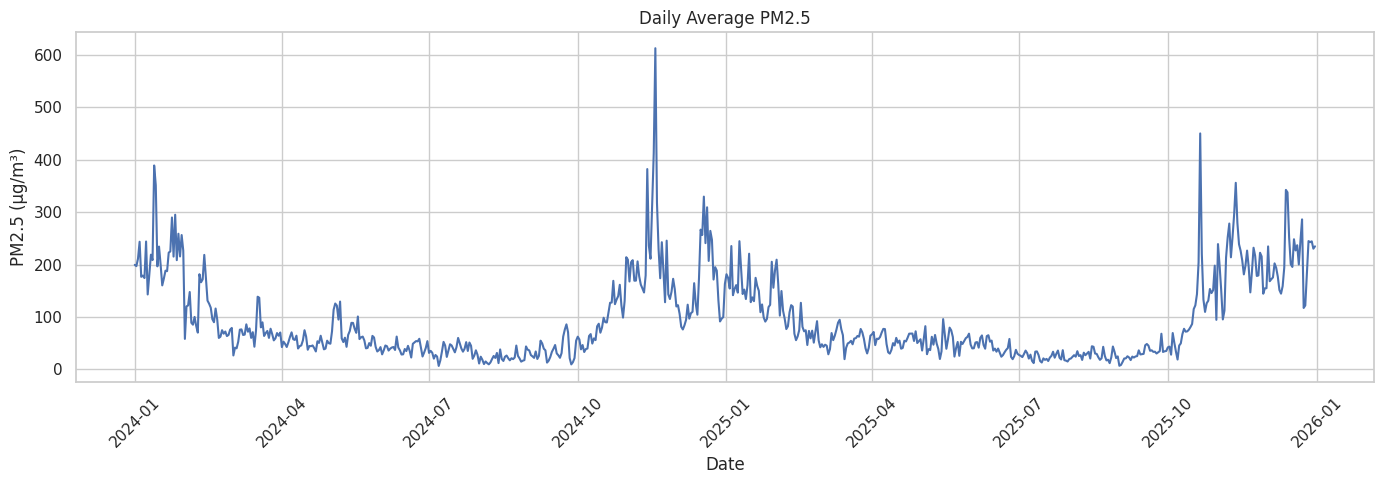

In [60]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily["Date"],
    daily["PM2.5 (µg/m³)"]
)

plt.title("Daily Average PM2.5")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [61]:
df["Month_Start"] = df["Timestamp"].dt.to_period("M").dt.to_timestamp()

/tmp/ipykernel_2044/2030573668.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["Month_Start"] = df["Timestamp"].dt.to_period("M").dt.to_timestamp()


In [62]:
monthly = df.groupby(
    ["Month_Start", "Station ID"]
).agg({
    "PM2.5 (µg/m³)": "mean",
    "PM10 (µg/m³)": "mean",
    "NO2 (µg/m³)": "mean",
    "CO (mg/m³)": "mean",
    "Pollution_Score": "mean"
}).reset_index()

monthly.head()

,Month_Start,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score
0,2024-01-01,site_1563,221.589046,392.178259,138.881838,1.686205,0.268905
1,2024-02-01,site_1563,107.062500,258.605424,112.665320,1.834427,0.180977
2,2024-03-01,site_1563,70.538810,202.140121,75.146976,1.620509,0.133618
3,2024-04-01,site_1563,50.746875,209.835764,76.475938,0.920207,0.117477
4,2024-05-01,site_1563,69.058972,257.049395,72.184341,0.838686,0.133695


In [63]:
highest_months = monthly.sort_values(
    "Pollution_Score",
    ascending=False
).head(10)

highest_months[
    [
        "Month_Start",
        "Station ID",
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "Pollution_Score"
    ]
]

,Month_Start,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),Pollution_Score
0,2024-01-01,site_1563,221.589046,392.178259,138.881838,0.268905
22,2025-11-01,site_1563,209.586979,353.847917,91.592969,0.235988
23,2025-12-01,site_1563,210.270665,354.051747,83.070497,0.230479
10,2024-11-01,site_1563,219.832812,343.304340,74.249913,0.228843
1,2024-02-01,site_1563,107.062500,258.605424,112.665320,0.180977
11,2024-12-01,site_1563,159.679099,266.802923,73.086475,0.176390
12,2025-01-01,site_1563,154.554435,269.130376,64.865827,0.169811
21,2025-10-01,site_1563,110.138441,227.979335,47.555511,0.141697
4,2024-05-01,site_1563,69.058972,257.049395,72.184341,0.133695
2,2024-03-01,site_1563,70.538810,202.140121,75.146976,0.133618


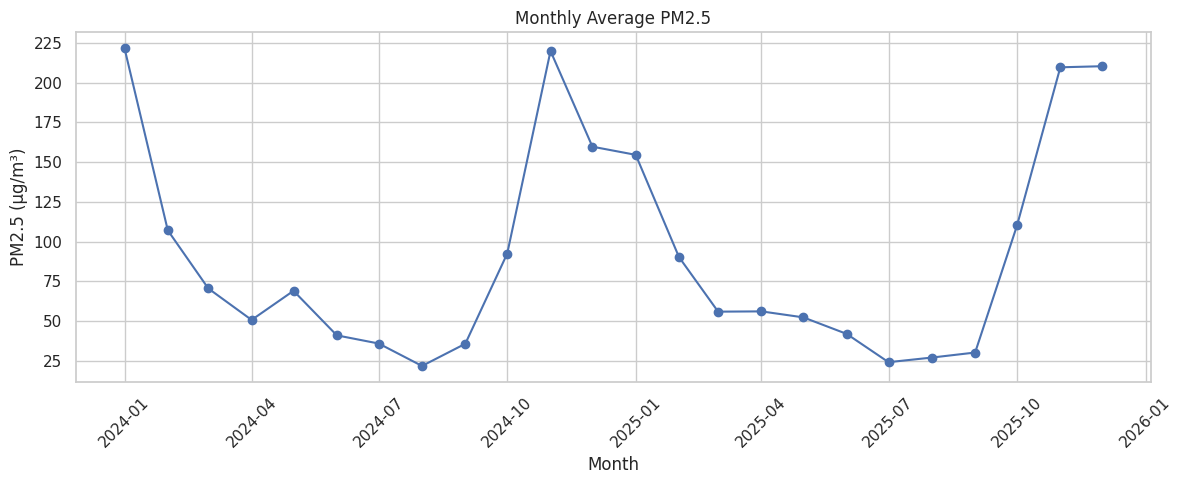

In [64]:
monthly_pm25 = df.groupby(
    "Month_Start"
)["PM2.5 (µg/m³)"].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pm25.index,
    monthly_pm25.values,
    marker="o"
)

plt.title("Monthly Average PM2.5")
plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [65]:
monthly_pollutants = df.groupby(
    "Month_Start"
)[
    [
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "CO (mg/m³)"
    ]
].mean()

monthly_pollutants.head()

,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³)
Month_Start,,,,
2024-01-01,221.589046,392.178259,138.881838,1.686205
2024-02-01,107.062500,258.605424,112.665320,1.834427
2024-03-01,70.538810,202.140121,75.146976,1.620509
2024-04-01,50.746875,209.835764,76.475938,0.920207
2024-05-01,69.058972,257.049395,72.184341,0.838686


<Figure size 1400x600 with 0 Axes>

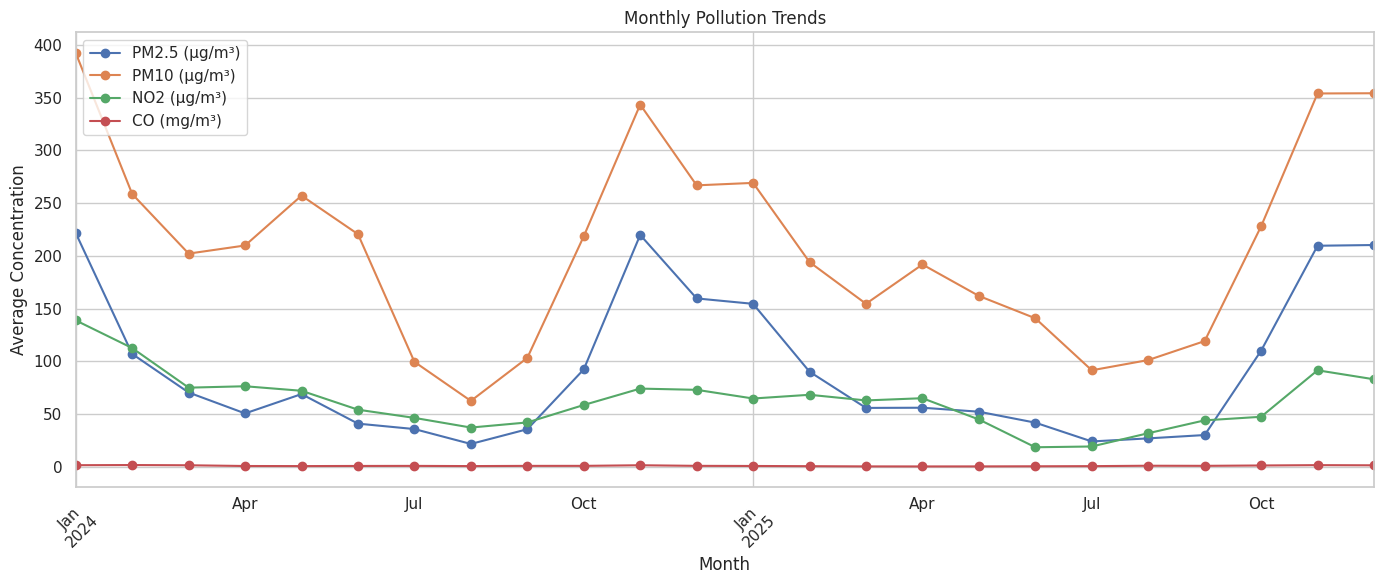

In [66]:
plt.figure(figsize=(14, 6))

monthly_pollutants.plot(
    marker="o",
    figsize=(14, 6)
)

plt.title("Monthly Pollution Trends")
plt.xlabel("Month")
plt.ylabel("Average Concentration")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [67]:
worst_month = monthly_pm25.idxmax()
worst_value = monthly_pm25.max()

print("Worst Month:", worst_month)
print("Average PM2.5:", worst_value)

Worst Month: 2024-01-01 00:00:00
Average PM2.5: 221.58904569892474


In [68]:
best_month = monthly_pm25.idxmin()
best_value = monthly_pm25.min()

print("Lowest Pollution Month:", best_month)
print("Average PM2.5:", best_value)

Lowest Pollution Month: 2024-08-01 00:00:00
Average PM2.5: 21.821908602150536


In [69]:
monthly_report = df.groupby(
    "Month_Start"
).agg({
    "PM2.5 (µg/m³)": "mean",
    "PM10 (µg/m³)": "mean",
    "NO2 (µg/m³)": "mean",
    "CO (mg/m³)": "mean",
    "Pollution_Score": "mean"
}).reset_index()

monthly_report = monthly_report.sort_values(
    "Pollution_Score",
    ascending=False
)

monthly_report

,Month_Start,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score
0,2024-01-01,221.589046,392.178259,138.881838,1.686205,0.268905
22,2025-11-01,209.586979,353.847917,91.592969,1.736009,0.235988
23,2025-12-01,210.270665,354.051747,83.070497,1.580482,0.230479
10,2024-11-01,219.832812,343.304340,74.249913,1.633651,0.228843
1,2024-02-01,107.062500,258.605424,112.665320,1.834427,0.180977
11,2024-12-01,159.679099,266.802923,73.086475,1.067618,0.176390
12,2025-01-01,154.554435,269.130376,64.865827,0.951994,0.169811
21,2025-10-01,110.138441,227.979335,47.555511,1.417816,0.141697
4,2024-05-01,69.058972,257.049395,72.184341,0.838686,0.133695
2,2024-03-01,70.538810,202.140121,75.146976,1.620509,0.133618


In [70]:
daily.to_csv(
    "daily_pollution_analysis.csv",
    index=False
)

monthly_report.to_csv(
    "monthly_pollution_analysis.csv",
    index=False
)

print("Daily and monthly analysis files saved!")

Daily and monthly analysis files saved!


In [71]:
station_summary = df.groupby("Station ID").agg({
    "PM2.5 (µg/m³)": "mean",
    "PM10 (µg/m³)": "mean",
    "NO2 (µg/m³)": "mean",
    "CO (mg/m³)": "mean",
    "Pollution_Score": "mean"
}).reset_index()

station_summary

,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score
0,site_1563,91.199548,208.025051,62.581084,1.0944,0.130269


In [72]:
station_summary = station_summary.sort_values(
    "Pollution_Score",
    ascending=False
).reset_index(drop=True)

station_summary

,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score
0,site_1563,91.199548,208.025051,62.581084,1.0944,0.130269


In [73]:
def hotspot_level(score):
    if score >= 0.75:
        return "Critical"
    elif score >= 0.50:
        return "High"
    elif score >= 0.25:
        return "Moderate"
    else:
        return "Low"


station_summary["Hotspot_Level"] = (
    station_summary["Pollution_Score"]
    .apply(hotspot_level)
)

station_summary

,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score,Hotspot_Level
0,site_1563,91.199548,208.025051,62.581084,1.0944,0.130269,Low


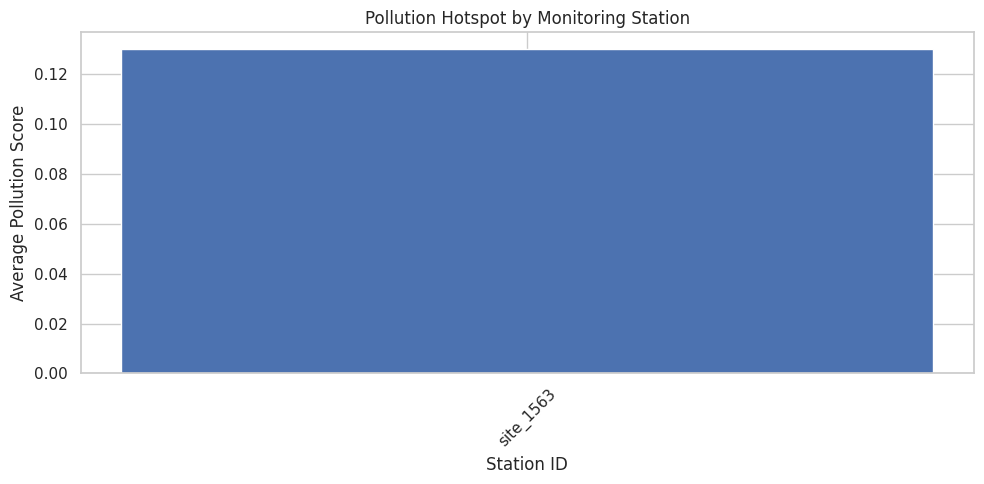

In [74]:
plt.figure(figsize=(10, 5))

plt.bar(
    station_summary["Station ID"].astype(str),
    station_summary["Pollution_Score"]
)

plt.title("Pollution Hotspot by Monitoring Station")
plt.xlabel("Station ID")
plt.ylabel("Average Pollution Score")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [75]:
worst_station = station_summary.iloc[0]

print("Highest Pollution Station:")
print("Station:", worst_station["Station ID"])
print("Pollution Score:", worst_station["Pollution_Score"])
print("Hotspot Level:", worst_station["Hotspot_Level"])

Highest Pollution Station:
Station: site_1563
Pollution Score: 0.13026914079503973
Hotspot Level: Low


In [76]:
df["PM25_ZScore"] = df.groupby(
    "Station ID"
)["PM2.5 (µg/m³)"].transform(
    lambda x: (x - x.mean()) / x.std()
)

In [77]:
episodes = df[
    df["PM25_ZScore"] > 3
].copy()

print("Number of unusual pollution observations:", len(episodes))

Number of unusual pollution observations: 1010


In [79]:
episodes[
    [
        "Timestamp",
        "Station ID",
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "CO (mg/m³)",
        "AT (°C)",
        "RH (%)",
        "WS (m/s)",
        "RF (mm)",
        "PM25_ZScore"
    ]
].head(20)

,Timestamp,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),AT (°C),RH (%),WS (m/s),RF (mm),PM25_ZScore
251,2024-01-03 14:45:00+00:00,site_1563,364.0,598.0,48.7,2.8,16.1,11.4,1.0,0.0,3.122560
252,2024-01-03 15:00:00+00:00,site_1563,364.0,598.0,58.4,2.4,16.2,8.8,1.1,0.0,3.122560
253,2024-01-03 15:15:00+00:00,site_1563,364.0,598.0,54.5,2.4,16.0,8.8,1.0,0.0,3.122560
254,2024-01-03 15:30:00+00:00,site_1563,364.0,598.0,61.9,2.5,16.0,9.7,0.7,0.0,3.122560
727,2024-01-08 13:45:00+00:00,site_1563,354.0,649.0,66.1,2.0,17.3,2.9,0.9,0.0,3.008097
728,2024-01-08 14:00:00+00:00,site_1563,354.0,649.0,62.2,2.1,17.4,2.8,0.8,0.0,3.008097
729,2024-01-08 14:15:00+00:00,site_1563,354.0,649.0,70.0,1.8,17.5,2.7,0.7,0.0,3.008097
730,2024-01-08 14:30:00+00:00,site_1563,354.0,649.0,66.5,1.7,17.3,2.9,0.5,0.0,3.008097
731,2024-01-08 14:45:00+00:00,site_1563,371.0,679.0,62.0,1.6,17.2,2.8,0.2,0.0,3.202684
732,2024-01-08 15:00:00+00:00,site_1563,371.0,679.0,62.3,1.5,17.4,2.8,0.4,0.0,3.202684


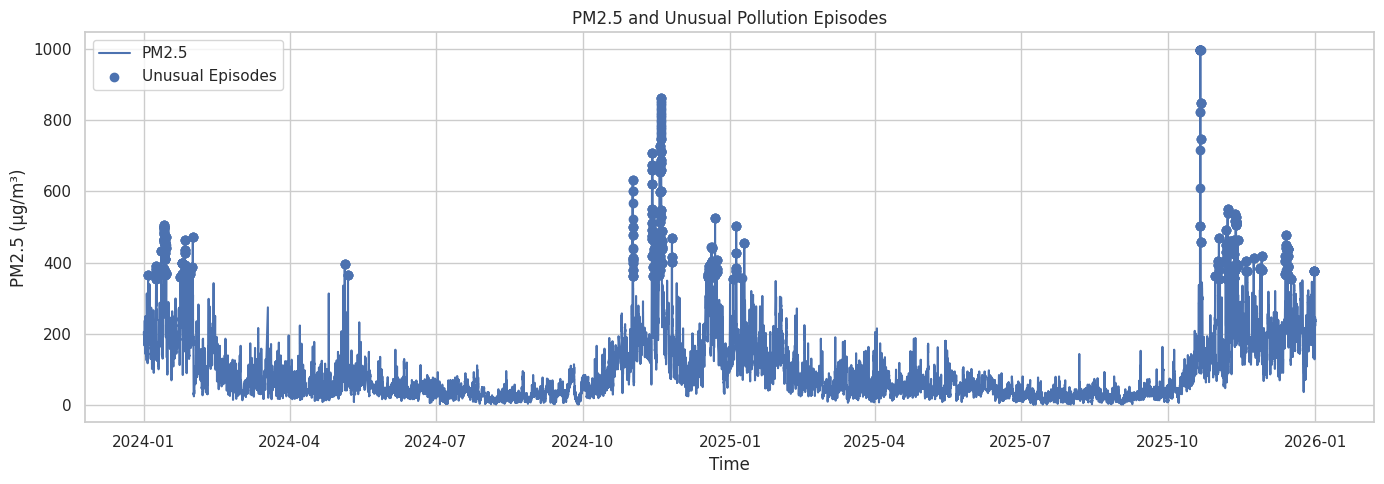

In [80]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp"],
    df["PM2.5 (µg/m³)"],
    label="PM2.5"
)

plt.scatter(
    episodes["Timestamp"],
    episodes["PM2.5 (µg/m³)"],
    label="Unusual Episodes"
)

plt.title("PM2.5 and Unusual Pollution Episodes")
plt.xlabel("Time")
plt.ylabel("PM2.5 (µg/m³)")

plt.legend()

plt.tight_layout()
plt.show()

In [81]:
episode_by_station = (
    episodes["Station ID"]
    .value_counts()
    .reset_index()
)

episode_by_station.columns = [
    "Station ID",
    "Episode_Count"
]

episode_by_station

,Station ID,Episode_Count
0,site_1563,1010


In [82]:
episodes["Episode_Date"] = (
    episodes["Timestamp"].dt.date
)

episode_days = (
    episodes.groupby("Episode_Date")
    .size()
    .reset_index(name="Episode_Count")
    .sort_values(
        "Episode_Count",
        ascending=False
    )
)

episode_days.head(10)

,Episode_Date,Episode_Count
23,2024-11-18,96
22,2024-11-17,56
3,2024-01-13,53
43,2025-11-12,52
4,2024-01-14,51
18,2024-11-13,44
42,2025-11-11,44
50,2025-12-13,42
36,2025-10-21,40
21,2024-11-16,40


In [83]:
hotspot_report = station_summary[
    [
        "Station ID",
        "PM2.5 (µg/m³)",
        "PM10 (µg/m³)",
        "NO2 (µg/m³)",
        "CO (mg/m³)",
        "Pollution_Score",
        "Hotspot_Level"
    ]
].copy()

hotspot_report

,Station ID,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Pollution_Score,Hotspot_Level
0,site_1563,91.199548,208.025051,62.581084,1.0944,0.130269,Low


In [84]:
station_summary.to_csv(
    "station_hotspot_analysis.csv",
    index=False
)

episodes.to_csv(
    "unusual_pollution_episodes.csv",
    index=False
)

print("Step 6 files saved successfully!")

Step 6 files saved successfully!


In [85]:
weather_pollution = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "AT (°C)",
    "RH (%)",
    "WS (m/s)",
    "RF (mm)"
]

correlation = df[weather_pollution].corr()

correlation

,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),AT (°C),RH (%),WS (m/s),RF (mm)
PM2.5 (µg/m³),1.000000,0.832615,0.388586,0.336112,-0.574171,0.038329,-0.269977,-0.013663
PM10 (µg/m³),0.832615,1.000000,0.504458,0.358886,-0.411099,-0.212625,-0.171357,-0.012873
NO2 (µg/m³),0.388586,0.504458,1.000000,0.339872,-0.315580,-0.302551,-0.142120,0.033075
CO (mg/m³),0.336112,0.358886,0.339872,1.000000,-0.231575,0.036770,-0.194461,-0.009892
AT (°C),-0.574171,-0.411099,-0.315580,-0.231575,1.000000,-0.224930,0.249666,-0.037959
RH (%),0.038329,-0.212625,-0.302551,0.036770,-0.224930,1.000000,-0.302155,-0.006714
WS (m/s),-0.269977,-0.171357,-0.142120,-0.194461,0.249666,-0.302155,1.000000,0.060169
RF (mm),-0.013663,-0.012873,0.033075,-0.009892,-0.037959,-0.006714,0.060169,1.000000


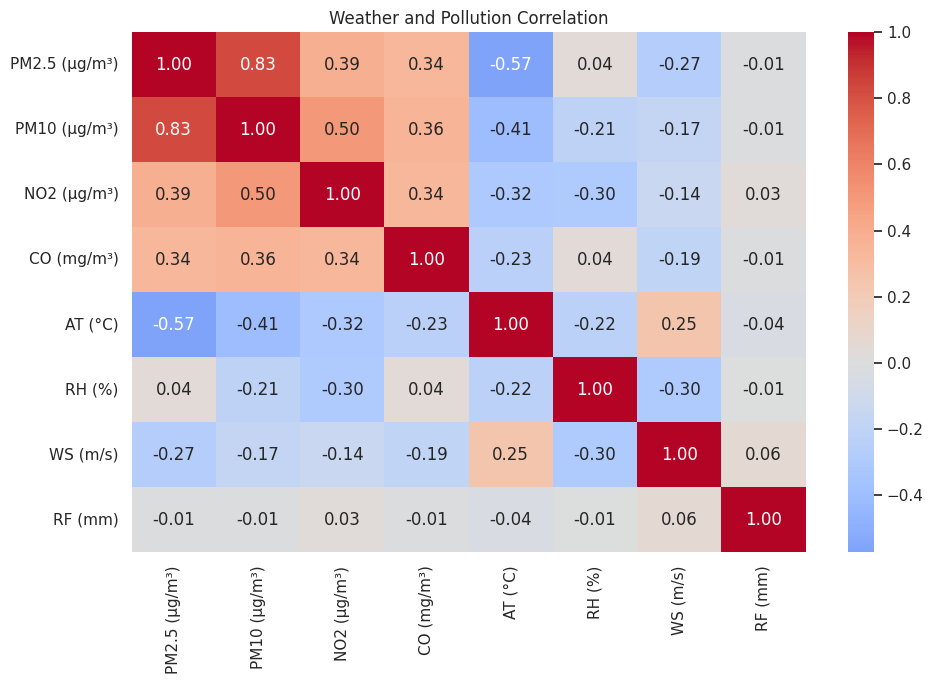

In [86]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Weather and Pollution Correlation")

plt.tight_layout()
plt.show()

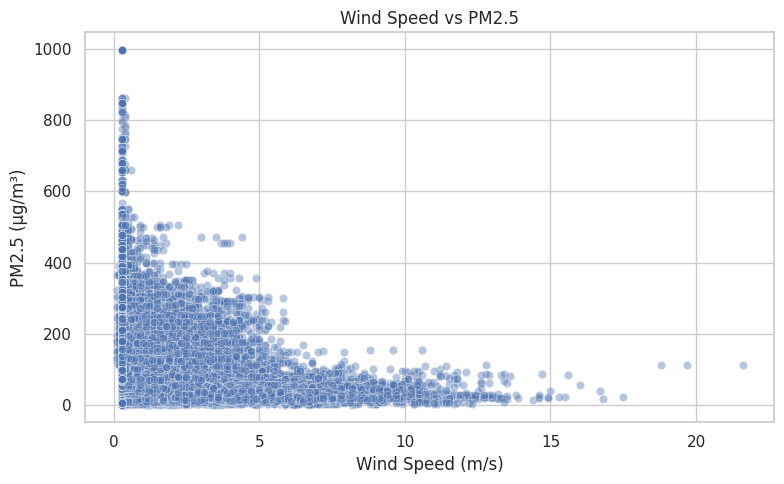

In [87]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="WS (m/s)",
    y="PM2.5 (µg/m³)",
    alpha=0.4
)

plt.title("Wind Speed vs PM2.5")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

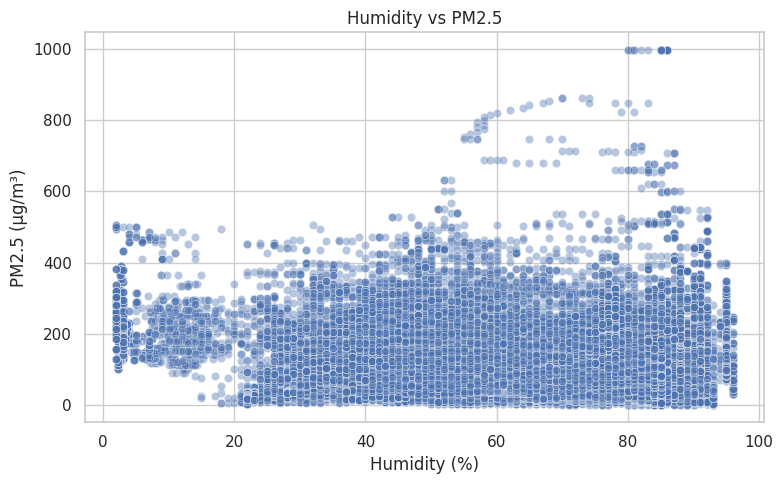

In [88]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="RH (%)",
    y="PM2.5 (µg/m³)",
    alpha=0.4
)

plt.title("Humidity vs PM2.5")
plt.xlabel("Humidity (%)")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

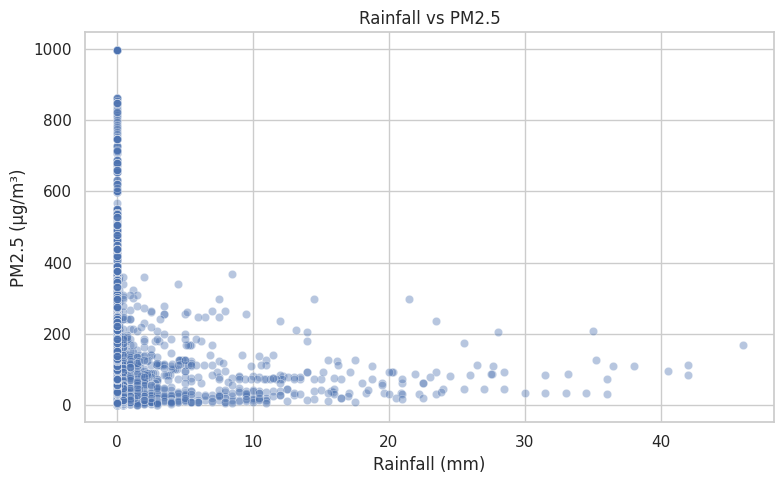

In [89]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="RF (mm)",
    y="PM2.5 (µg/m³)",
    alpha=0.4
)

plt.title("Rainfall vs PM2.5")
plt.xlabel("Rainfall (mm)")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

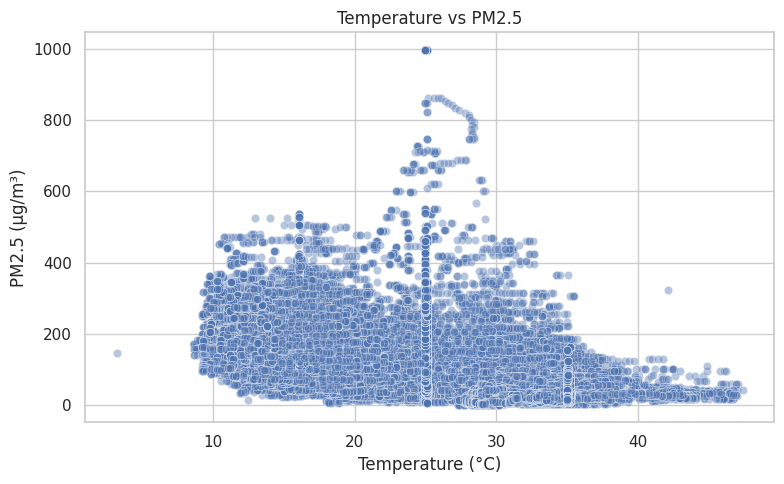

In [90]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="AT (°C)",
    y="PM2.5 (µg/m³)",
    alpha=0.4
)

plt.title("Temperature vs PM2.5")
plt.xlabel("Temperature (°C)")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

In [91]:
print("PM2.5 correlations:")
print(
    correlation["PM2.5 (µg/m³)"]
    .sort_values(ascending=False)
)

PM2.5 correlations:
PM2.5 (µg/m³)    1.000000
PM10 (µg/m³)     0.832615
NO2 (µg/m³)      0.388586
CO (mg/m³)       0.336112
RH (%)           0.038329
RF (mm)         -0.013663
WS (m/s)        -0.269977
AT (°C)         -0.574171
Name: PM2.5 (µg/m³), dtype: float64


In [92]:
correlation.to_csv(
    "weather_pollution_correlation.csv"
)

print("Weather correlation results saved!")

Weather correlation results saved!


In [93]:
df = df.sort_values("Timestamp").reset_index(drop=True)

In [94]:
df["Next_Hour_Risk"] = (
    df.groupby("Station ID")["Risk_Level"].shift(-1)
)

In [95]:
df[[
    "Timestamp",
    "Risk_Level",
    "Next_Hour_Risk"
]].head(10)

,Timestamp,Risk_Level,Next_Hour_Risk
0,2024-01-01 00:00:00+00:00,Low,Low
1,2024-01-01 00:15:00+00:00,Low,Low
2,2024-01-01 00:30:00+00:00,Low,Low
3,2024-01-01 00:45:00+00:00,Low,Low
4,2024-01-01 01:00:00+00:00,Low,Low
5,2024-01-01 01:15:00+00:00,Low,Low
6,2024-01-01 01:30:00+00:00,Low,Low
7,2024-01-01 01:45:00+00:00,Low,Low
8,2024-01-01 02:00:00+00:00,Low,Low
9,2024-01-01 02:15:00+00:00,Low,Low


In [96]:
df_model = df.dropna(
    subset=["Next_Hour_Risk"]
).copy()

print("Model records:", len(df_model))

Model records: 70175


In [97]:
features = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "AT (°C)",
    "RH (%)",
    "WS (m/s)",
    "RF (mm)",
    "Hour",
    "DayOfWeek",
    "Month"
]

X = df_model[features]
y = df_model["Next_Hour_Risk"]

In [98]:
print(y.value_counts())

Next_Hour_Risk
Low         64261
Moderate     5716
High          198
Name: count, dtype: int64


In [99]:
split_index = int(len(df_model) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records :", len(X_test))

Training records: 56140
Testing records : 14035


In [100]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [101]:
y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [102]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(20)

,Actual,Predicted
0,Low,Low
1,Low,Low
2,Low,Low
3,Low,Low
4,Low,Low
5,Low,Low
6,Low,Low
7,Low,Low
8,Low,Low
9,Low,Low


In [103]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Random Forest Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Random Forest Accuracy: 96.16 %

Classification Report:
              precision    recall  f1-score   support

        High       0.31      0.15      0.20        34
         Low       0.97      0.99      0.98     11988
    Moderate       0.90      0.82      0.86      2013

    accuracy                           0.96     14035
   macro avg       0.73      0.65      0.68     14035
weighted avg       0.96      0.96      0.96     14035



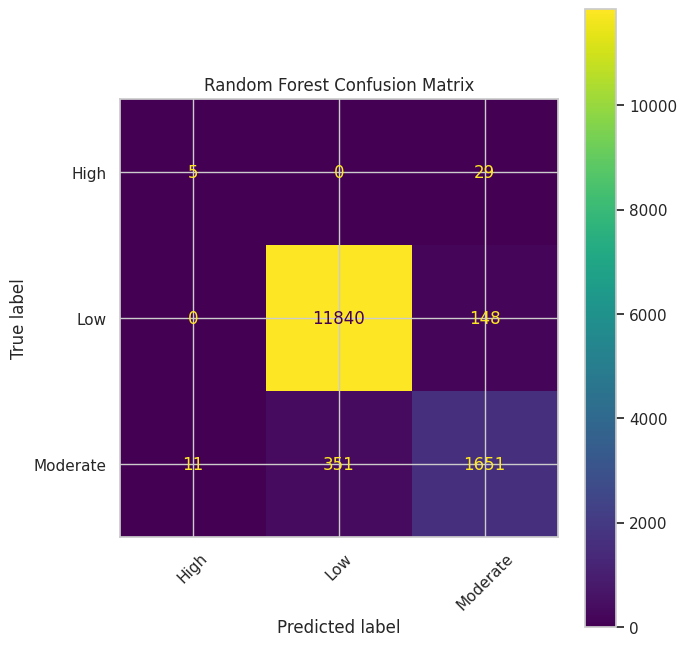

In [105]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

# Create the plot
fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [106]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

Feature Importance:
PM10 (µg/m³)     0.328959
PM2.5 (µg/m³)    0.289482
NO2 (µg/m³)      0.118421
CO (mg/m³)       0.088085
AT (°C)          0.075330
Month            0.036622
RH (%)           0.026002
Hour             0.016586
WS (m/s)         0.011093
DayOfWeek        0.008771
RF (mm)          0.000649
dtype: float64


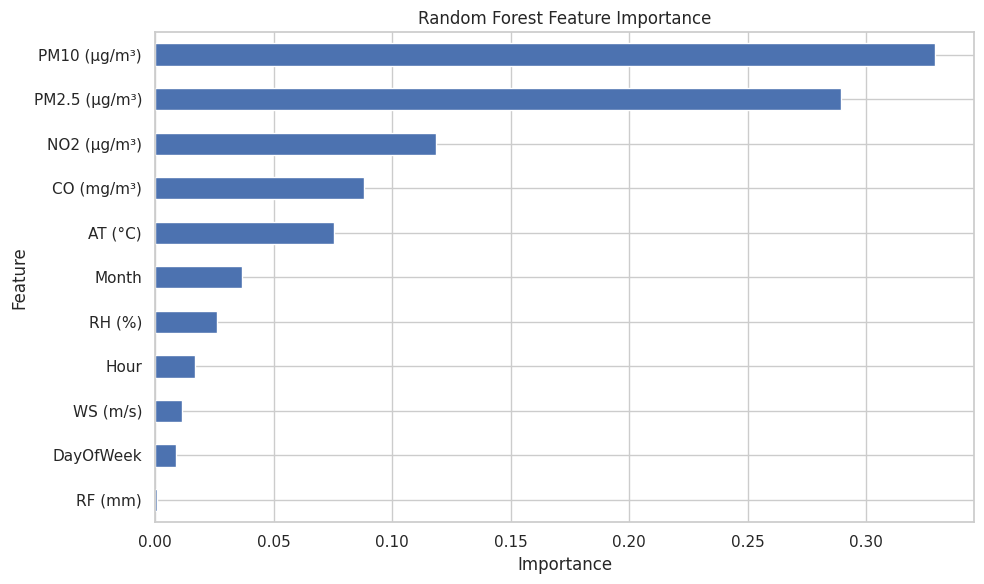

In [107]:
plt.figure(figsize=(10, 6))

importance.sort_values().plot(
    kind="barh"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [108]:
import joblib

joblib.dump(
    model,
    "airguard_random_forest.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [109]:
prediction_results = df_model.iloc[split_index:].copy()

prediction_results["Predicted_Risk"] = y_pred

prediction_results[
    [
        "Timestamp",
        "Station ID",
        "Risk_Level",
        "Next_Hour_Risk",
        "Predicted_Risk"
    ]
].to_csv(
    "random_forest_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


In [110]:
from google.colab import files

files.download("airguard_random_forest.pkl")
files.download("random_forest_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

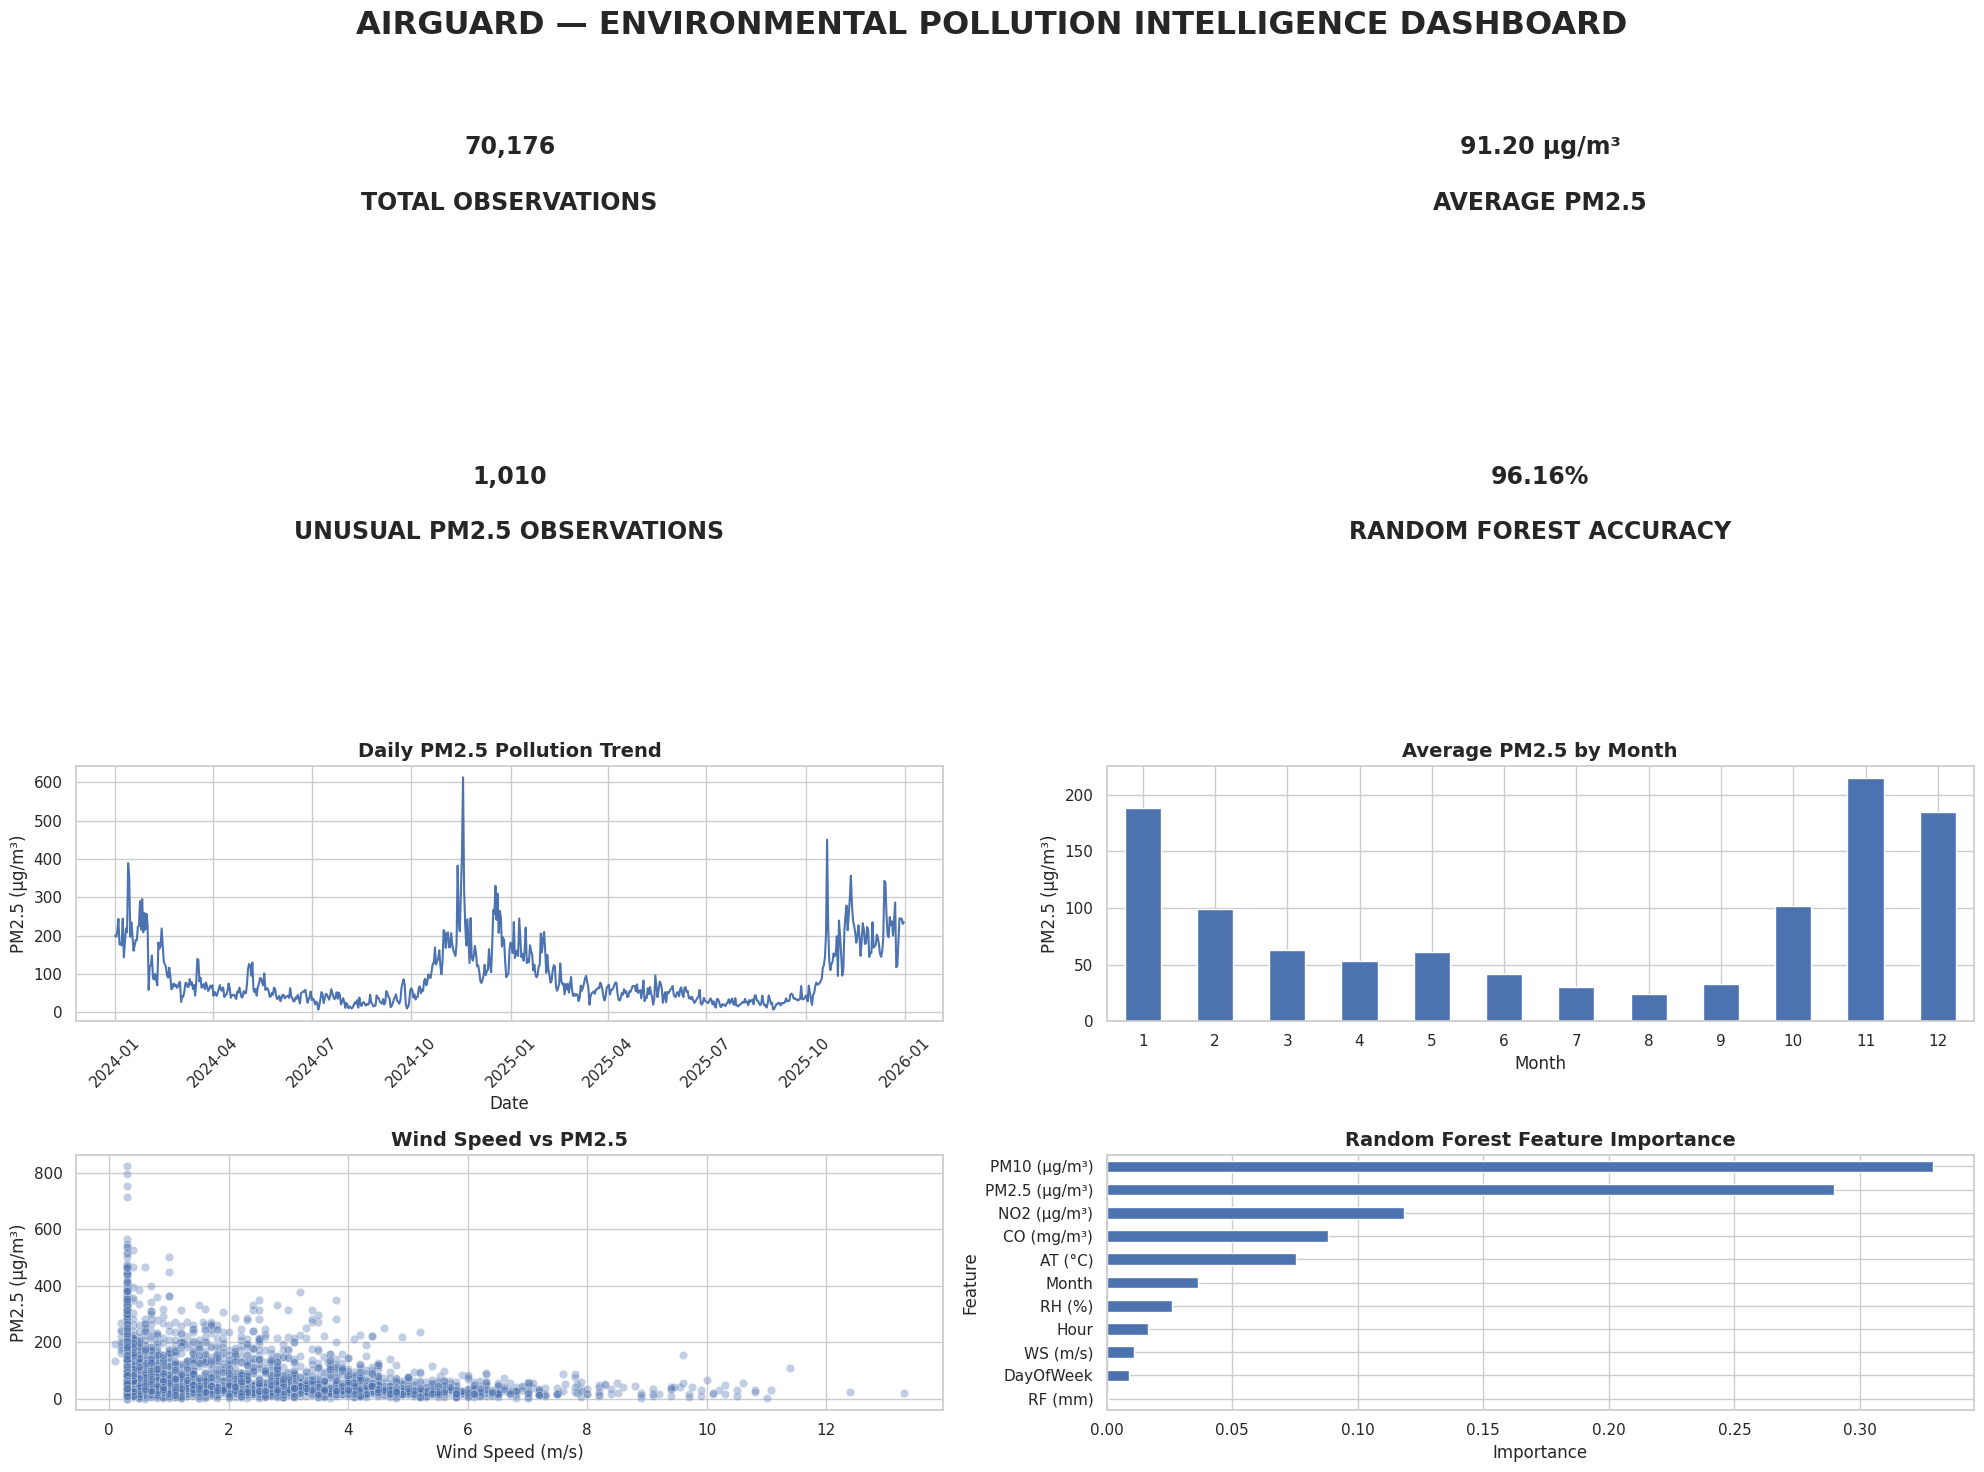

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# ============================================================
# AIRGUARD — ENVIRONMENTAL POLLUTION INTELLIGENCE DASHBOARD
# ============================================================

# ------------------------------------------------------------
# Basic calculations
# ------------------------------------------------------------

total_records = len(df)

total_stations = df["Station ID"].nunique()

avg_pm25 = df["PM2.5 (µg/m³)"].mean()

avg_pm10 = df["PM10 (µg/m³)"].mean()

avg_no2 = df["NO2 (µg/m³)"].mean()

avg_co = df["CO (mg/m³)"].mean()

avg_pollution_score = df["Pollution_Score"].mean()

total_unusual = len(episodes)

model_accuracy = accuracy * 100


# ============================================================
# CREATE DASHBOARD
# ============================================================

fig = plt.figure(figsize=(20, 15))

gs = fig.add_gridspec(
    4,
    2,
    height_ratios=[0.8, 1.5, 1.5, 1.5]
)

fig.suptitle(
    "AIRGUARD — ENVIRONMENTAL POLLUTION INTELLIGENCE DASHBOARD",
    fontsize=23,
    fontweight="bold"
)


# ============================================================
# KPI 1 — TOTAL RECORDS
# ============================================================

ax1 = fig.add_subplot(gs[0, 0])

ax1.text(
    0.5,
    0.5,
    f"{total_records:,}\n\nTOTAL OBSERVATIONS",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

ax1.axis("off")


# ============================================================
# KPI 2 — AVERAGE PM2.5
# ============================================================

ax2 = fig.add_subplot(gs[0, 1])

ax2.text(
    0.5,
    0.5,
    f"{avg_pm25:.2f} µg/m³\n\nAVERAGE PM2.5",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

ax2.axis("off")


# ============================================================
# KPI 3 — UNUSUAL OBSERVATIONS
# ============================================================

ax3 = fig.add_subplot(gs[1, 0])

ax3.text(
    0.5,
    0.5,
    f"{total_unusual:,}\n\nUNUSUAL PM2.5 OBSERVATIONS",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

ax3.axis("off")


# ============================================================
# KPI 4 — RANDOM FOREST ACCURACY
# ============================================================

ax4 = fig.add_subplot(gs[1, 1])

ax4.text(
    0.5,
    0.5,
    f"{model_accuracy:.2f}%\n\nRANDOM FOREST ACCURACY",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

ax4.axis("off")


# ============================================================
# CHART 1 — DAILY PM2.5 TREND
# ============================================================

ax5 = fig.add_subplot(gs[2, 0])

daily_pm25 = (
    df.groupby("Date")["PM2.5 (µg/m³)"]
    .mean()
)

ax5.plot(
    daily_pm25.index,
    daily_pm25.values,
    linewidth=1.5
)

ax5.set_title(
    "Daily PM2.5 Pollution Trend",
    fontsize=14,
    fontweight="bold"
)

ax5.set_xlabel("Date")
ax5.set_ylabel("PM2.5 (µg/m³)")

ax5.tick_params(axis="x", rotation=45)


# ============================================================
# CHART 2 — MONTHLY POLLUTION
# ============================================================

ax6 = fig.add_subplot(gs[2, 1])

monthly_pm25 = (
    df.groupby("Month")["PM2.5 (µg/m³)"]
    .mean()
)

monthly_pm25.plot(
    kind="bar",
    ax=ax6
)

ax6.set_title(
    "Average PM2.5 by Month",
    fontsize=14,
    fontweight="bold"
)

ax6.set_xlabel("Month")
ax6.set_ylabel("PM2.5 (µg/m³)")

ax6.tick_params(axis="x", rotation=0)


# ============================================================
# CHART 3 — WEATHER VS PM2.5
# ============================================================

ax7 = fig.add_subplot(gs[3, 0])

sns.scatterplot(
    data=df.sample(
        min(5000, len(df)),
        random_state=42
    ),
    x="WS (m/s)",
    y="PM2.5 (µg/m³)",
    alpha=0.35,
    ax=ax7
)

ax7.set_title(
    "Wind Speed vs PM2.5",
    fontsize=14,
    fontweight="bold"
)

ax7.set_xlabel("Wind Speed (m/s)")
ax7.set_ylabel("PM2.5 (µg/m³)")


# ============================================================
# CHART 4 — RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

ax8 = fig.add_subplot(gs[3, 1])

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(
    ascending=True
)

importance.plot(
    kind="barh",
    ax=ax8
)

ax8.set_title(
    "Random Forest Feature Importance",
    fontsize=14,
    fontweight="bold"
)

ax8.set_xlabel("Importance")
ax8.set_ylabel("Feature")


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()

In [119]:
# ============================================================
# STEP 10.1 — KEY INSIGHTS FROM THE DATA
# ============================================================

# 1. Overall pollution averages
print("===== OVERALL POLLUTION =====")
print(f"Average PM2.5 : {df['PM2.5 (µg/m³)'].mean():.2f}")
print(f"Average PM10  : {df['PM10 (µg/m³)'].mean():.2f}")
print(f"Average NO2   : {df['NO2 (µg/m³)'].mean():.2f}")
print(f"Average CO    : {df['CO (mg/m³)'].mean():.2f}")

# 2. Highest pollution month
monthly_pollution = df.groupby("Month")["PM2.5 (µg/m³)"].mean()

highest_month = monthly_pollution.idxmax()
highest_month_value = monthly_pollution.max()

lowest_month = monthly_pollution.idxmin()
lowest_month_value = monthly_pollution.min()

print("\n===== MONTHLY PATTERN =====")
print(f"Highest PM2.5 month : {highest_month} ({highest_month_value:.2f})")
print(f"Lowest PM2.5 month  : {lowest_month} ({lowest_month_value:.2f})")

# 3. Highest pollution hour
hourly_pollution = df.groupby("Hour")["PM2.5 (µg/m³)"].mean()

highest_hour = hourly_pollution.idxmax()
highest_hour_value = hourly_pollution.max()

print("\n===== HOURLY PATTERN =====")
print(f"Highest PM2.5 hour : {highest_hour}:00 ({highest_hour_value:.2f})")

# 4. Weekday vs weekend
weekday_pm25 = df.loc[
    ~df["Is_Weekend"],
    "PM2.5 (µg/m³)"
].mean()

weekend_pm25 = df.loc[
    df["Is_Weekend"],
    "PM2.5 (µg/m³)"
].mean()

print("\n===== WEEKDAY vs WEEKEND =====")
print(f"Weekday PM2.5 : {weekday_pm25:.2f}")
print(f"Weekend PM2.5 : {weekend_pm25:.2f}")

# 5. Unusual observations
print("\n===== UNUSUAL POLLUTION =====")
print(f"Unusual PM2.5 observations : {len(episodes):,}")

# 6. Highest pollution day
daily_pm25 = df.groupby("Date")["PM2.5 (µg/m³)"].mean()

highest_day = daily_pm25.idxmax()
highest_day_value = daily_pm25.max()

print("\n===== HIGHEST POLLUTION DAY =====")
print(f"Date : {highest_day}")
print(f"Average PM2.5 : {highest_day_value:.2f}")

# 7. Weather correlations
weather_corr = df[
    [
        "PM2.5 (µg/m³)",
        "AT (°C)",
        "RH (%)",
        "WS (m/s)",
        "RF (mm)"
    ]
].corr()["PM2.5 (µg/m³)"].drop("PM2.5 (µg/m³)")

print("\n===== WEATHER CORRELATION WITH PM2.5 =====")
print(weather_corr.sort_values(ascending=False))

# 8. Random Forest
print("\n===== MACHINE LEARNING =====")
print(f"Random Forest Accuracy : {accuracy * 100:.2f}%")

===== OVERALL POLLUTION =====
Average PM2.5 : 91.20
Average PM10  : 208.03
Average NO2   : 62.58
Average CO    : 1.09

===== MONTHLY PATTERN =====
Highest PM2.5 month : 11 (214.71)
Lowest PM2.5 month  : 8 (24.46)

===== HOURLY PATTERN =====
Highest PM2.5 hour : 10:00 (106.96)

===== WEEKDAY vs WEEKEND =====
Weekday PM2.5 : 90.83
Weekend PM2.5 : 92.12

===== UNUSUAL POLLUTION =====
Unusual PM2.5 observations : 1,010

===== HIGHEST POLLUTION DAY =====
Date : 2024-11-18
Average PM2.5 : 612.58

===== WEATHER CORRELATION WITH PM2.5 =====
RH (%)      0.038329
RF (mm)    -0.013663
WS (m/s)   -0.269977
AT (°C)    -0.574171
Name: PM2.5 (µg/m³), dtype: float64

===== MACHINE LEARNING =====
Random Forest Accuracy : 96.16%


In [120]:
# ============================================================
# STEP 10.2 — PRACTICAL ACTION PLAN
# ============================================================

print("=" * 70)
print("AIRGUARD — PRACTICAL POLLUTION ACTION PLAN")
print("=" * 70)

print("\n1. POLLUTION MONITORING")
print("- Monitor PM2.5 and PM10 continuously.")
print("- Give special attention to periods with unusually high PM2.5.")
print("- Use the Random Forest model for next-hour risk prediction.")

print("\n2. HIGH-RISK PERIOD MANAGEMENT")
print("- Identify hours with consistently high pollution.")
print("- Issue early warnings before predicted high-risk periods.")
print("- Increase monitoring during recurring pollution episodes.")

print("\n3. WEATHER-BASED RESPONSE")
print("- Track wind speed, rainfall, humidity and temperature.")
print("- Use weather conditions together with pollution measurements.")
print("- Low-dispersion conditions can trigger additional monitoring.")

print("\n4. UNUSUAL POLLUTION EPISODES")
print("- Investigate detected PM2.5 anomalies.")
print("- Compare unusual episodes with weather conditions.")
print("- Check for possible local emission sources during these periods.")

print("\n5. DATA-DRIVEN DECISION MAKING")
print("- Use daily and monthly pollution trends for planning.")
print("- Use station-level analysis to identify monitoring priorities.")
print("- Continuously retrain the model as new observations become available.")

print("\n6. PUBLIC AWARENESS")
print("- Provide pollution risk information through dashboards.")
print("- Alert sensitive groups during high-risk periods.")
print("- Encourage reduced outdoor exposure during severe pollution episodes.")

print("\n7. FUTURE IMPROVEMENTS")
print("- Add more monitoring stations and geographic coordinates.")
print("- Integrate real-time air-quality data.")
print("- Add traffic and industrial emission data.")
print("- Test additional machine-learning models.")

AIRGUARD — PRACTICAL POLLUTION ACTION PLAN

1. POLLUTION MONITORING
- Monitor PM2.5 and PM10 continuously.
- Give special attention to periods with unusually high PM2.5.
- Use the Random Forest model for next-hour risk prediction.

2. HIGH-RISK PERIOD MANAGEMENT
- Identify hours with consistently high pollution.
- Issue early warnings before predicted high-risk periods.
- Increase monitoring during recurring pollution episodes.

3. WEATHER-BASED RESPONSE
- Track wind speed, rainfall, humidity and temperature.
- Use weather conditions together with pollution measurements.
- Low-dispersion conditions can trigger additional monitoring.

4. UNUSUAL POLLUTION EPISODES
- Investigate detected PM2.5 anomalies.
- Compare unusual episodes with weather conditions.
- Check for possible local emission sources during these periods.

5. DATA-DRIVEN DECISION MAKING
- Use daily and monthly pollution trends for planning.
- Use station-level analysis to identify monitoring priorities.
- Continuously retr

In [121]:
# ============================================================
# STEP 10.3 — FINAL KEY INSIGHTS
# ============================================================

print("=" * 75)
print("AIRGUARD — FINAL KEY INSIGHTS")
print("=" * 75)

# ------------------------------------------------------------
# INSIGHT 1 — Overall pollution
# ------------------------------------------------------------

avg_pm25 = df["PM2.5 (µg/m³)"].mean()
avg_pm10 = df["PM10 (µg/m³)"].mean()

print("\n1. OVERALL POLLUTION LEVEL")
print(
    f"Average PM2.5 concentration was {avg_pm25:.2f} µg/m³ "
    f"while average PM10 concentration was {avg_pm10:.2f} µg/m³."
)

# ------------------------------------------------------------
# INSIGHT 2 — Monthly pattern
# ------------------------------------------------------------

monthly_pm25 = df.groupby("Month")["PM2.5 (µg/m³)"].mean()

highest_month = monthly_pm25.idxmax()
highest_month_value = monthly_pm25.max()

lowest_month = monthly_pm25.idxmin()
lowest_month_value = monthly_pm25.min()

print("\n2. SEASONAL / MONTHLY PATTERN")
print(
    f"Month {highest_month} recorded the highest average PM2.5 "
    f"({highest_month_value:.2f} µg/m³), while Month {lowest_month} "
    f"recorded the lowest ({lowest_month_value:.2f} µg/m³)."
)

# ------------------------------------------------------------
# INSIGHT 3 — Hourly pattern
# ------------------------------------------------------------

hourly_pm25 = df.groupby("Hour")["PM2.5 (µg/m³)"].mean()

highest_hour = hourly_pm25.idxmax()
highest_hour_value = hourly_pm25.max()

lowest_hour = hourly_pm25.idxmin()
lowest_hour_value = hourly_pm25.min()

print("\n3. HOURLY POLLUTION PATTERN")
print(
    f"PM2.5 reached its highest hourly average around "
    f"{highest_hour}:00 ({highest_hour_value:.2f} µg/m³)."
)

# ------------------------------------------------------------
# INSIGHT 4 — Weekday vs weekend
# ------------------------------------------------------------

weekday_pm25 = df.loc[
    ~df["Is_Weekend"],
    "PM2.5 (µg/m³)"
].mean()

weekend_pm25 = df.loc[
    df["Is_Weekend"],
    "PM2.5 (µg/m³)"
].mean()

print("\n4. WEEKDAY VS WEEKEND")
print(
    f"Average weekday PM2.5 was {weekday_pm25:.2f} µg/m³, "
    f"compared with {weekend_pm25:.2f} µg/m³ on weekends."
)

# ------------------------------------------------------------
# INSIGHT 5 — Unusual pollution episodes
# ------------------------------------------------------------

print("\n5. UNUSUAL POLLUTION EPISODES")
print(
    f"{len(episodes):,} unusual PM2.5 observations were detected "
    f"using a station-specific z-score threshold greater than 3."
)

# ------------------------------------------------------------
# INSIGHT 6 — Weather relationship
# ------------------------------------------------------------

weather_columns = [
    "AT (°C)",
    "RH (%)",
    "WS (m/s)",
    "RF (mm)"
]

weather_corr = df[
    ["PM2.5 (µg/m³)"] + weather_columns
].corr()["PM2.5 (µg/m³)"].drop("PM2.5 (µg/m³)")

strongest_weather = weather_corr.abs().idxmax()
strongest_value = weather_corr[strongest_weather]

print("\n6. WEATHER RELATIONSHIP")
print(
    f"{strongest_weather} showed the strongest linear correlation "
    f"with PM2.5 (correlation = {strongest_value:.3f})."
)

# ------------------------------------------------------------
# INSIGHT 7 — Machine Learning
# ------------------------------------------------------------

print("\n7. MACHINE LEARNING PREDICTION")
print(
    f"The Random Forest model achieved an accuracy of "
    f"{accuracy * 100:.2f}% for next-hour pollution risk classification."
)

print("\n" + "=" * 75)
print("KEY INSIGHTS GENERATED SUCCESSFULLY")
print("=" * 75)

AIRGUARD — FINAL KEY INSIGHTS

1. OVERALL POLLUTION LEVEL
Average PM2.5 concentration was 91.20 µg/m³ while average PM10 concentration was 208.03 µg/m³.

2. SEASONAL / MONTHLY PATTERN
Month 11 recorded the highest average PM2.5 (214.71 µg/m³), while Month 8 recorded the lowest (24.46 µg/m³).

3. HOURLY POLLUTION PATTERN
PM2.5 reached its highest hourly average around 10:00 (106.96 µg/m³).

4. WEEKDAY VS WEEKEND
Average weekday PM2.5 was 90.83 µg/m³, compared with 92.12 µg/m³ on weekends.

5. UNUSUAL POLLUTION EPISODES
1,010 unusual PM2.5 observations were detected using a station-specific z-score threshold greater than 3.

6. WEATHER RELATIONSHIP
AT (°C) showed the strongest linear correlation with PM2.5 (correlation = -0.574).

7. MACHINE LEARNING PREDICTION
The Random Forest model achieved an accuracy of 96.16% for next-hour pollution risk classification.

KEY INSIGHTS GENERATED SUCCESSFULLY
